# 01 · Exploratory Data Analysis — Does Twitter popularity reach the ballot box?

**Data:** #Secim2023 (ViralLab, Sabancı University) — daily profile snapshots of ~1,750 Turkish political accounts,
July 2022 – June 2023 · **Enrichment:** list of the 600 MPs elected on 14 May 2023 (Turkish Wikipedia).

Questions explored here:
1. What does the data cover, and how clean is it?
2. How did follower counts move around the key events (6 Feb earthquake, campaign start, 14 & 28 May rounds)?
3. Did campaign-period follower growth differ across parties?
4. Did politicians who were elected in May 2023 grow faster during the campaign than those who were not?

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, matplotlib.dates as mdates
from scipy import stats
from pathlib import Path

ROOT = Path('..'); FIG = ROOT / 'figures'; FIG.mkdir(exist_ok=True)
daily = pd.concat([pd.read_csv(f, parse_dates=['date'], dtype={'id': str}) for f in sorted((ROOT / 'data/processed').glob('daily_panel_*.csv.gz'))], ignore_index=True)
acc   = pd.read_csv(ROOT / 'data/processed/accounts.csv', dtype={'id': str})
feat  = pd.read_csv(ROOT / 'data/processed/account_features.csv', dtype={'id': str})

EVENTS = {'Earthquake\n6 Feb': '2023-02-06', 'Campaign\n10 Mar': '2023-03-10',
          'Round 1\n14 May': '2023-05-14', 'Round 2\n28 May': '2023-05-28'}
# validated categorical palette (fixed order, party identity); labels are always shown next to marks
PARTY_COLOR = {'AKP': '#F28C00', 'CHP': '#E30A17', 'HDP': '#7A2E8C', 'GELECEK': '#1F9D55', 'MHP': '#A0522D',
               'DEVA': '#0077B6', 'ZAFER': '#E879A6', 'MEMLEKET': '#4F5BD5', 'IYI': '#2EC4D6'}
INK, MUTED, GRID = '#1f2328', '#6e7781', '#e6e8eb'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
                     'font.size': 10, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
                     'text.color': INK, 'axes.labelcolor': INK, 'figure.dpi': 110})

def mark_events(ax, labels=True):
    for lab, d in EVENTS.items():
        ax.axvline(pd.Timestamp(d), color=MUTED, lw=1, ls='--', zorder=0)
        if labels:
            ax.text(pd.Timestamp(d), 1.0, lab, transform=ax.get_xaxis_transform(), fontsize=8,
                    color=MUTED, ha='center', va='bottom')

print(f"{len(daily):,} daily snapshots · {daily.id.nunique():,} accounts · {daily.date.min():%d %b %Y} – {daily.date.max():%d %b %Y}")

424,502 daily snapshots · 1,758 accounts · 01 Jul 2022 – 30 Jun 2023


## 1 · Coverage and data quality

In [2]:
cov = daily.groupby(daily.date.dt.to_period('M')).agg(accounts=('id', 'nunique'), snapshots=('id', 'size'))
cov['snapshots_per_account'] = (cov.snapshots / cov.accounts).round(1)
display(cov)

print('Missing values per column:'); display(daily.isna().sum().to_frame('n_missing').T)
print('Accounts matched to a party in the official account list:', acc.party.notna().sum(), '/', len(acc))
display(acc.role.value_counts(dropna=False).rename('accounts').to_frame())

,accounts,snapshots,snapshots_per_account
date,,,
2022-07,934,28954,31.0
2022-08,934,28954,31.0
2022-09,934,28020,30.0
2022-10,934,28954,31.0
2022-11,1387,32204,23.2
2022-12,1383,42797,30.9
2023-01,1384,42735,30.9
2023-02,1407,39262,27.9
2023-03,1406,43425,30.9


Missing values per column:


,id,date,followers,friends,tweets,listed,favourites
n_missing,0,0,0,0,0,0,0


Accounts matched to a party in the official account list: 1284 / 1758


,accounts
role,
district_politician,889
NaN,403
other_politician,248
party_executive,154
media,64


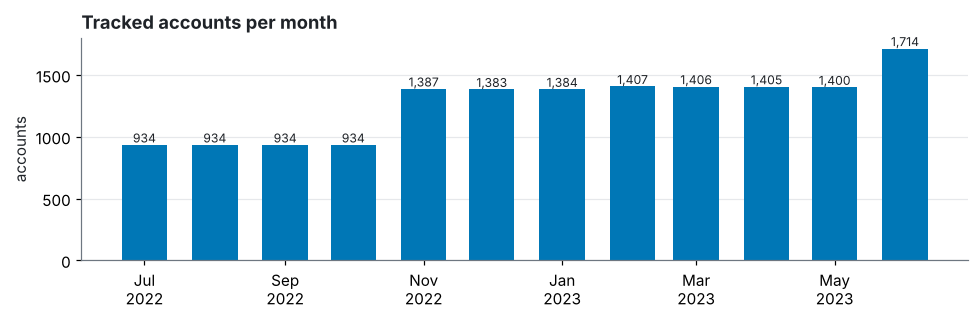

In [3]:
fig, ax = plt.subplots(figsize=(9, 3))
x = cov.index.to_timestamp()
ax.bar(x, cov.accounts, width=20, color='#0077B6')
for xi, v in zip(x, cov.accounts):
    ax.text(xi, v + 20, f'{v:,}', ha='center', fontsize=8, color=INK)
ax.set_title('Tracked accounts per month'); ax.set_ylabel('accounts'); ax.grid(axis='x', visible=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b\n%Y'))
plt.tight_layout(); plt.savefig(FIG / '01_coverage.png', dpi=200); plt.show()

The account list was expanded in **Nov 2022** (934 → ~1,390) and again in **Jun 2023** (→ 1,714).
To avoid mixing different populations, growth comparisons below use only accounts observed at **both** ends of each window.

## 2 · How big are these accounts?

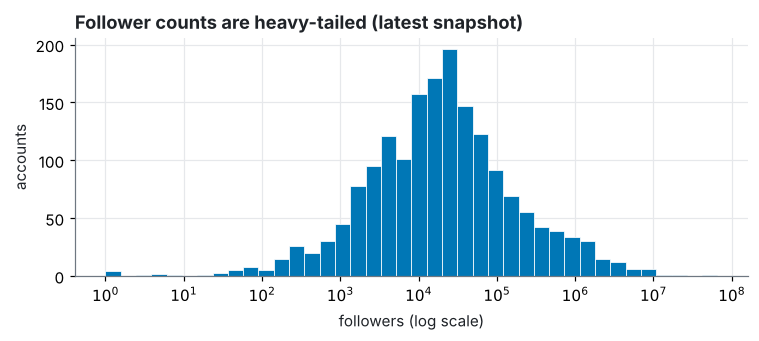

,count,mean,std,min,25%,50%,75%,90%,99%,max
followers,1758.0,242367.0,1802889.0,0.0,4716.0,19322.0,66740.0,339887.0,4035292.0,65639957.0


In [4]:
last = daily.sort_values('date').groupby('id').last()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(np.log10(last.followers.clip(lower=1)), bins=40, color='#0077B6', edgecolor='white', linewidth=0.5)
ax.set_xticks(range(0, 9)); ax.set_xticklabels([f'$10^{k}$' for k in range(0, 9)])
ax.set_title('Follower counts are heavy-tailed (latest snapshot)'); ax.set_xlabel('followers (log scale)'); ax.set_ylabel('accounts')
plt.tight_layout(); plt.savefig(FIG / '02_follower_distribution.png', dpi=200); plt.show()
display(last.followers.describe(percentiles=[.25, .5, .75, .9, .99]).round(0).to_frame('followers').T)

A few leaders hold tens of millions of followers while the median account has tens of thousands, so
**raw follower counts are not comparable**. All later comparisons use **relative (%) growth** and non-parametric tests.

## 3 · Follower trajectories around the key events

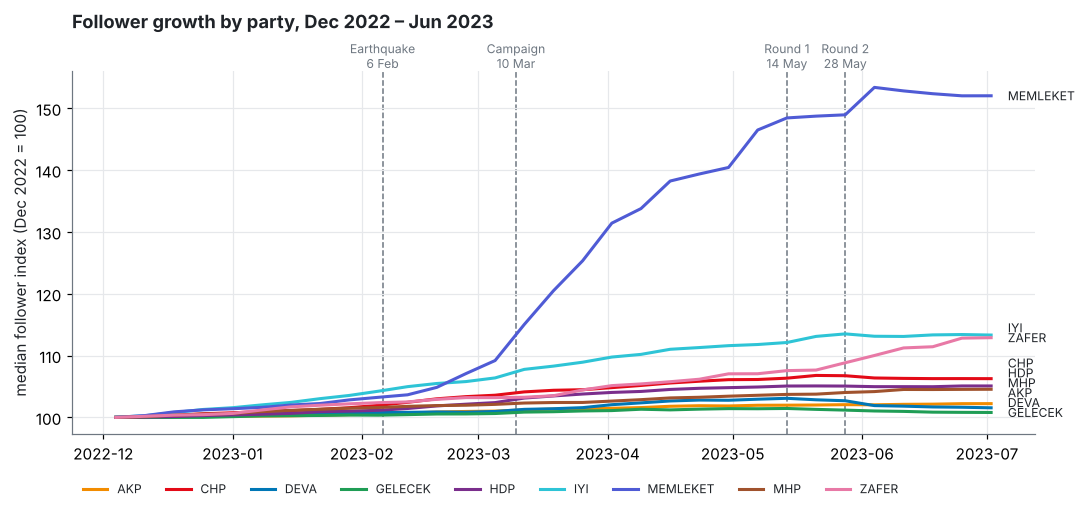

In [5]:
# Index each account to 100 on its first snapshot in Dec 2022, then take the party median
panel = daily[daily.date >= '2022-12-01'].merge(acc[['id', 'party']], on='id')
panel = panel[panel.party.isin(PARTY_COLOR)]
base = panel.sort_values('date').groupby('id').followers.first()
panel['index'] = 100 * panel.followers / panel.id.map(base).clip(lower=1)
weekly = panel.groupby(['party', pd.Grouper(key='date', freq='W')])['index'].median().unstack(0)

fig, ax = plt.subplots(figsize=(10, 4.8))
ends = weekly.ffill().iloc[-1].sort_values()
for p in weekly.columns:
    ax.plot(weekly.index, weekly[p], color=PARTY_COLOR[p], lw=2, label=p)
# direct labels at line ends, nudged apart so they do not collide
y_prev = -1e9
for p, y in ends.items():
    y = max(y, y_prev + 1.6); y_prev = y
    ax.text(weekly.index[-1] + pd.Timedelta(days=4), y, p, color=INK, fontsize=8, va='center')
mark_events(ax)
ax.set_ylabel('median follower index (Dec 2022 = 100)')
ax.set_title('Follower growth by party, Dec 2022 – Jun 2023', pad=28)
ax.legend(ncol=9, fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(0, -0.1))
plt.tight_layout(); plt.savefig(FIG / '03_party_trajectories.png', dpi=200, bbox_inches='tight'); plt.show()

**Observations**
- Memleket Partisi accounts climb fastest in March–April and flatten after Muharrem İnce withdrew (11 May).
- Most parties accelerate after the campaign officially starts; the large establishment parties (AKP, MHP) move least in relative terms.
- At the party level the earthquake week leaves no common jump — but the candidate view below shows it did matter for individual leaders.

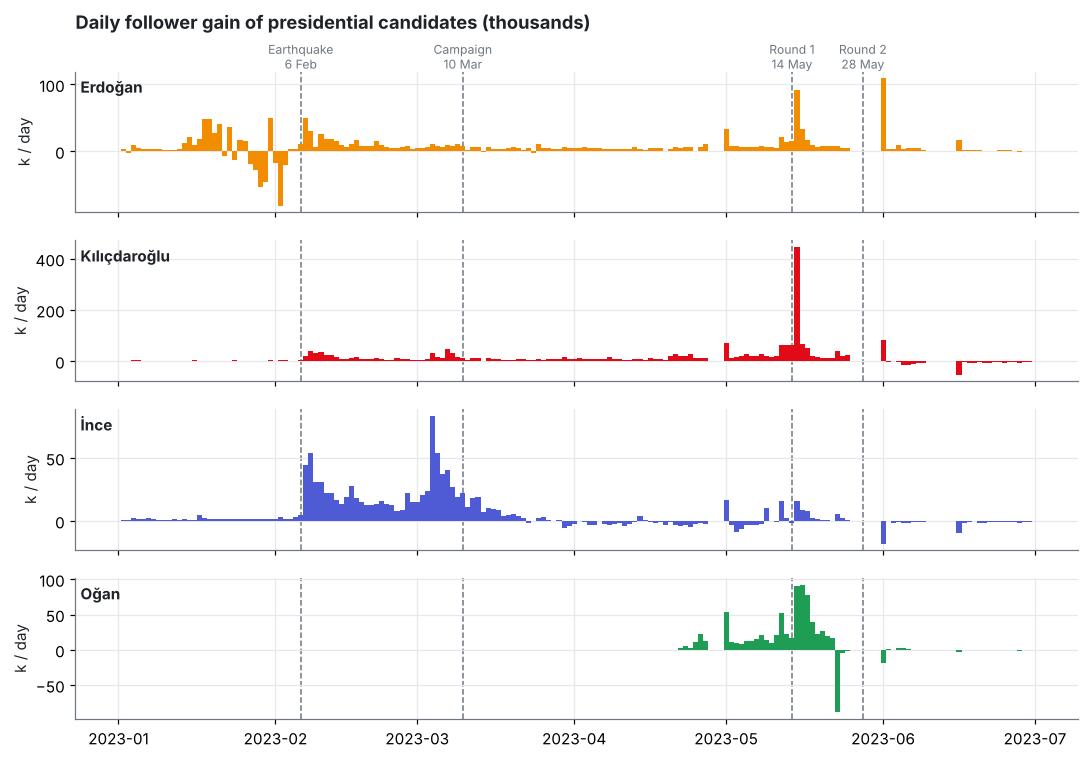

,total_gain_2023,best_day_gain,peak_day
who,,,
Erdoğan,1224735.0,109761.0,2023-06-01
Kılıçdaroğlu,2145360.0,446894.0,2023-05-15
Oğan,599080.0,92462.0,2023-05-16
İnce,909917.0,83465.0,2023-03-04


In [6]:
# Daily follower change of the four presidential candidates
cands = {'RTErdogan': 'Erdoğan', 'kilicdarogluk': 'Kılıçdaroğlu', 'vekilince': 'İnce', 'DrSinanOgan': 'Oğan'}
cand_color = {'Erdoğan': '#F28C00', 'Kılıçdaroğlu': '#E30A17', 'İnce': '#4F5BD5', 'Oğan': '#1F9D55'}
ids = acc[acc.screen_name.isin(cands)].set_index('id').screen_name.map(cands)
c = daily[daily.id.isin(ids.index) & (daily.date >= '2023-01-01')].copy()
c['who'] = c.id.map(ids)
c = c.sort_values('date'); c['gain'] = c.groupby('who').followers.diff()

fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
for ax, who in zip(axes, cand_color):
    s = c[c.who == who]
    ax.bar(s.date, s.gain / 1e3, width=1, color=cand_color[who])
    ax.set_ylabel('k / day'); ax.text(0.005, 0.85, who, transform=ax.transAxes, fontweight='bold')
    mark_events(ax, labels=(ax is axes[0]))
axes[0].set_title('Daily follower gain of presidential candidates (thousands)', pad=28)
plt.tight_layout(); plt.savefig(FIG / '04_candidates_daily_gain.png', dpi=200); plt.show()
display(c.groupby('who').gain.agg(['sum', 'max', 'idxmax']).assign(peak_day=lambda d: c.loc[d['idxmax'], 'date'].values)
         .drop(columns='idxmax').rename(columns={'sum': 'total_gain_2023', 'max': 'best_day_gain'}))

**Observations** (gain = change between consecutive snapshots; blank stretches are collection gaps)
- **Kılıçdaroğlu's** biggest day (~+447k) came right after Round 1 on 15 May; **Oğan** surged the same days as the kingmaker, then lost followers after endorsing Erdoğan.
- **İnce** gained most right after the earthquake and around his early-March campaign launch, then turned negative before withdrawing — the follower market moved *before* the ballot did.
- **Erdoğan** shows net *losses* in late January (likely an account purge by the platform) and his peak after his re-election.

## 4 · Campaign-period growth by party  *(preview of H1)*

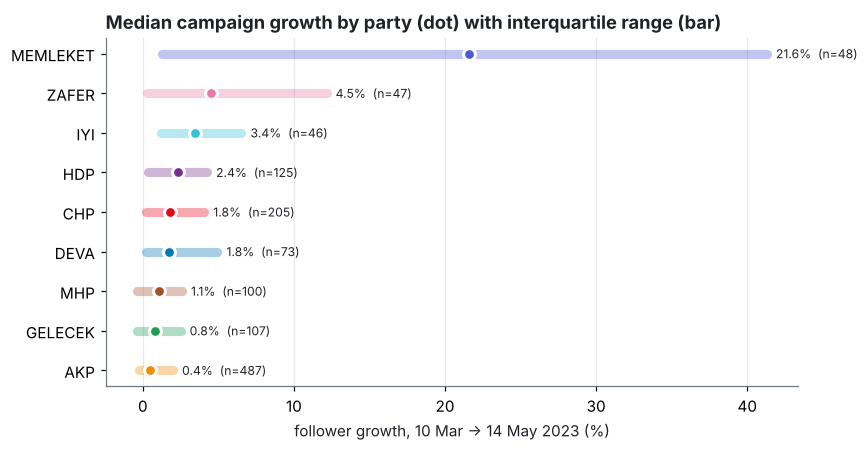

Kruskal–Wallis across 9 parties: H = 136.1, p = 1.53e-25


In [7]:
f = feat[feat.party.isin(PARTY_COLOR) & feat.campaign_follower_growth_pct.notna()]
order = f.groupby('party').campaign_follower_growth_pct.median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 4.2))
for i, p in enumerate(order):
    v = f.loc[f.party == p, 'campaign_follower_growth_pct']
    q1, med, q3 = v.quantile([.25, .5, .75])
    ax.plot([q1, q3], [i, i], color=PARTY_COLOR[p], lw=6, alpha=0.35, solid_capstyle='round')
    ax.scatter(med, i, s=60, color=PARTY_COLOR[p], edgecolor='white', linewidth=2, zorder=3)
    ax.text(q3 + 0.6, i, f'{med:.1f}%  (n={len(v)})', va='center', fontsize=8, color=INK)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.grid(axis='y', visible=False)
ax.set_xlabel('follower growth, 10 Mar → 14 May 2023 (%)')
ax.set_title('Median campaign growth by party (dot) with interquartile range (bar)')
plt.tight_layout(); plt.savefig(FIG / '05_campaign_growth_by_party.png', dpi=200); plt.show()

H, p = stats.kruskal(*[g.campaign_follower_growth_pct for _, g in f.groupby('party')])
print(f'Kruskal–Wallis across {f.party.nunique()} parties: H = {H:.1f}, p = {p:.2e}')

## 5 · Elected vs. not elected  *(preview of H2)*

,n,median_growth,median_baseline,median_followers
group,,,,
Elected 14 May,253,2.97,2.40,46285.0
Not elected,772,0.65,0.65,24782.5


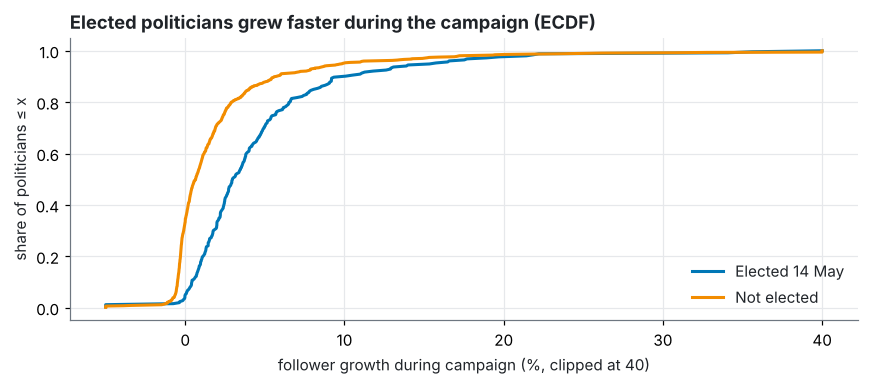

Mann–Whitney U (elected > not elected): U = 145,883, p = 1.93e-32


In [8]:
g = feat[feat.role.isin(['district_politician', 'party_executive']) & feat.campaign_follower_growth_pct.notna()].copy()
g['group'] = np.where(g.elected_2023, 'Elected 14 May', 'Not elected')
summary = g.groupby('group').agg(n=('id', 'size'), median_growth=('campaign_follower_growth_pct', 'median'),
                                 median_baseline=('baseline_follower_growth_pct', 'median'),
                                 median_followers=('campaign_followers_start', 'median')).round(2)
display(summary)

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = {'Elected 14 May': '#0077B6', 'Not elected': '#F28C00'}
for grp, col in colors.items():
    v = np.sort(g.loc[g.group == grp, 'campaign_follower_growth_pct'].clip(-5, 40))
    ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=col, lw=2, label=grp)
ax.set_xlabel('follower growth during campaign (%, clipped at 40)'); ax.set_ylabel('share of politicians ≤ x')
ax.set_title('Elected politicians grew faster during the campaign (ECDF)'); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / '06_elected_vs_not_ecdf.png', dpi=200); plt.show()

U, p = stats.mannwhitneyu(g.loc[g.elected_2023, 'campaign_follower_growth_pct'],
                          g.loc[~g.elected_2023, 'campaign_follower_growth_pct'], alternative='greater')
print(f'Mann–Whitney U (elected > not elected): U = {U:,.0f}, p = {p:.2e}')

**Caveat (important for the final analysis):** elected politicians were *already* growing faster before the candidate
lists were known (baseline Dec 2022 → 5 Feb 2023: median 2.4% vs 0.65%) and they start from larger accounts. So the gap
is not simply "campaign attention wins seats" — the final stage must control for party, baseline growth and size
(e.g. logistic regression) before claiming anything about the campaign itself.

## 6 · Summary of EDA findings and next steps
| Finding | Implication for the project |
|---|---|
| Follower counts are heavy-tailed (median ≈ tens of thousands, leaders ≫ 10M) | use % growth, log scales, non-parametric tests |
| Account coverage jumps in Nov 2022 and Jun 2023 | compare only accounts present in both ends of a window |
| Campaign growth differs strongly by party (Memleket ≫ AKP) | H1 — formal Kruskal–Wallis + Dunn post-hoc |
| Elected politicians grew faster — but already did so before the campaign | H2 — control for party, size and baseline growth |
| Candidate accounts show sharp single-day spikes around debates/withdrawals | event-study of daily gains (H3) |

**Next:** the elected-vs-not gap is examined properly in **[02_candidates_and_seats.ipynb](02_candidates_and_seats.ipynb)**,
using the official candidate lists and list ranks (closed-list PR), including a regression-discontinuity design at the seat cutoff.